# 15. Modelling: the pre-registered run and its result

**Question.** For each prediction task, does any model beat a simple rule, reliably, at 1, 3 and 6 months ahead, and how far can the forecasts be trusted?

The rules were fixed before any model was built (DL-78, `docs/modelling_plan.md`) and nothing was changed after the first result. The run covers three tasks at three horizons, with up to six scenarios each (the main run and robustness variants). It was run twice from the same code, data and seed (0; 2,000 bootstrap draws) and the two output files are byte-identical. This notebook only reads the stored results (`data/reference/modelling_results.json`) and one post-hoc file (`data/reference/modelling_posthoc.json`); it fits nothing.

Sections 2 to 4 are the registered results. **Section 5 is a post-hoc check, added after the results were seen**, and it changes how the T3 result should be read.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..")
R = json.loads((ROOT / "data" / "reference" / "modelling_results.json").read_text("utf-8"))
P = json.loads((ROOT / "data" / "reference" / "modelling_posthoc.json").read_text("utf-8"))
HS = ["1", "3", "6"]
COL = {"base": "#9aa7b1", "teal": "#0f8b8d", "blue": "#4f6d9a", "amber": "#e8a33d", "rust": "#c8553d"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9})
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("results for", R["meta"]["horizons"], "horizons; n_boot", R["meta"]["n_boot"], "seed", R["meta"]["seed"])

results for [1, 3, 6] horizons; n_boot 2000 seed 0


## 1. The rules, fixed beforehand

| | T1 national share | T2 segment share | T3 decline alert |
|---|---|---|---|
| Question | what will the share be? | what will each segment's share be? | will a segment's share fall by at least 30%? |
| Horizons | 1, 3, 6 months | 1, 3, 6 months | 1, 3, 6 months |
| Baselines | same as last month; same month last year | last month's share; the segment's, the specialty's long-run share; the market share | recent drop; small segment; always alert |
| Trained | ridge; ETS damped; ETS damped seasonal | logistic; gradient boosting; random forest | the same three classifiers |
| Primary score | mean absolute error | log-loss per visit | PR-AUC |
| Promotion | lower end of the paired gain above zero at the **1.67th** percentile (h = 1) or **0.83th** (h = 3, 6), whole months (T1: moving blocks) resampled | same | same |
| Serving | the simplest promoted model, else the best baseline | same | same |

The first origin is the 24th month of data, so test months are 46, 44, 41 (T2, T3) and 48, 46, 43 (T1).

In [2]:
counts = pd.DataFrame(R["counts"]).T
counts.index.name = "horizon"
counts = counts.rename(columns={
    "paired_rows": "paired rows", "t2_test_months": "T2 test months", "t3_scored_rows": "T3 scored rows",
    "t3_declines": "T3 declines", "t3_decline_share": "decline share (all)", "t3_test_months": "T3 test months",
    "t3_test_rows": "T3 test rows", "t3_test_declines": "T3 test declines"})
counts.style.format({"decline share (all)": "{:.3f}"}) if hasattr(counts, "style") else counts

,paired rows,T2 test months,decline share (all),T3 declines,T3 scored rows,T3 test declines,T3 test months,T3 test rows
horizon,,,,,,,,
1,8450.000000,46.000000,0.226,1117.000000,4944.000000,729.000000,46.000000,3183.000000
3,8218.000000,44.000000,0.225,1088.000000,4828.000000,735.000000,44.000000,3067.000000
6,7879.000000,41.000000,0.244,1136.000000,4654.000000,824.000000,41.000000,2893.000000


## 2. T1: the national share

Mean absolute error in percentage points (lower is better). *Gain* is the baseline's error minus the model's, so positive means better; *lower end* is the paired interval at the corrected percentile, the number the rule looks at.

In [3]:
rows = []
for h in HS:
    d = R["T1"][h]["scenarios"]["main"]
    best = d["best_baseline"]
    for name, m in d["models"].items():
        rows.append({"horizon": int(h), "model": name, "baseline": best, "baseline MAE": d["scores"][best]["mae"],
                     "model MAE": m["mae"], "gain": m["estimate"], "lower end": m["low"], "promoted": m["promoted"],
                     "90% range covers": d["scores"][name]["cover90"], "test months": d["n_test_months"]})
t1 = pd.DataFrame(rows)
t1

,horizon,model,baseline,baseline MAE,model MAE,gain,lower end,promoted,90% range covers,test months
0,1,ets_damped,last_month,0.1246,0.1583,-0.0338,-0.0760,False,0.8958,48
1,1,ets_seasonal,last_month,0.1246,0.1579,-0.0333,-0.0628,False,0.8125,48
2,1,ridge,last_month,0.1246,0.1466,-0.0220,-0.0516,False,0.9583,48
3,3,ets_damped,last_month,0.1802,0.2130,-0.0328,-0.0893,False,0.7609,46
4,3,ets_seasonal,last_month,0.1802,0.2323,-0.0521,-0.0993,False,0.7609,46
5,3,ridge,last_month,0.1802,0.2796,-0.0994,-0.1890,False,0.8261,46
6,6,ets_damped,last_month,0.2394,0.2630,-0.0237,-0.0926,False,0.7209,43
7,6,ets_seasonal,last_month,0.2394,0.2786,-0.0393,-0.0957,False,0.7674,43
8,6,ridge,last_month,0.2394,0.4017,-0.1623,-0.3475,False,0.4651,43


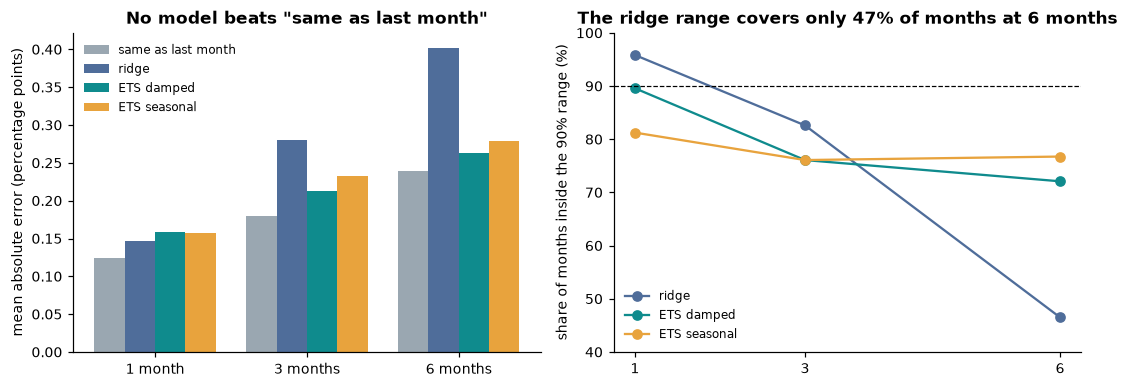

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
width = 0.2
for i, (label, key, color) in enumerate([("same as last month", None, COL["base"]), ("ridge", "ridge", COL["blue"]),
                                         ("ETS damped", "ets_damped", COL["teal"]), ("ETS seasonal", "ets_seasonal", COL["amber"])]):
    vals = [R["T1"][h]["scenarios"]["main"]["scores"][key or "last_month"]["mae"] for h in HS]
    ax[0].bar(np.arange(3) + (i - 1.5) * width, vals, width, label=label, color=color)
ax[0].set_xticks(range(3), [f"{h} month" + ("s" if h != "1" else "") for h in HS])
ax[0].set_ylabel("mean absolute error (percentage points)")
ax[0].set_title("No model beats \"same as last month\"")
ax[0].legend(frameon=False, fontsize=8)
for i, (label, key, color) in enumerate([("ridge", "ridge", COL["blue"]), ("ETS damped", "ets_damped", COL["teal"]),
                                         ("ETS seasonal", "ets_seasonal", COL["amber"])]):
    vals = [100 * R["T1"][h]["scenarios"]["main"]["scores"][key]["cover90"] for h in HS]
    ax[1].plot([int(h) for h in HS], vals, "o-", color=color, label=label)
ax[1].axhline(90, color="k", lw=0.8, ls="--")
ax[1].set_xticks([1, 3, 6])
ax[1].set_ylabel("share of months inside the 90% range (%)")
ax[1].set_title("The ridge range covers only 47% of months at 6 months")
ax[1].set_ylim(40, 100)
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** "Same as last month" has the lowest error at every horizon, and every model is worse than it. The ridge is the worst at 3 and 6 months. The 90% ranges should cover about 90% of months; the ridge's covers 47% at 6 months, so its range cannot be trusted there. The baseline serves the national number at all three horizons. This matches the feature test (DL-76) and the archive: the national share moves slowly and nothing we observe predicts its changes.

## 3. T2: the segment share

Binomial log-loss per visit (lower is better). The best baseline is "last month's share" at every horizon. *Gain* is positive when the model is better; *share of log-loss* is the gain as a percentage of the baseline's log-loss.

In [5]:
rows = []
for h in HS:
    d = R["T2"][h]["scenarios"]["main"]
    for name, m in d["models"].items():
        rows.append({"horizon": int(h), "model": name, "baseline log-loss": d["baseline_log_loss"][d["best_baseline"]],
                     "model log-loss": m["log_loss"], "gain": m["estimate"], "lower end": m["low"],
                     "share of log-loss %": 100 * m["relative_gain"], "months better": f'{m["months_better"]} / {d["n_test_months"]}',
                     "promoted": m["promoted"]})
t2 = pd.DataFrame(rows)
t2

,horizon,model,baseline log-loss,model log-loss,gain,lower end,share of log-loss %,months better,promoted
0,1,gbm,0.1132,0.1127,0.0005,0.0004,0.4354,46 / 46,True
1,1,logistic,0.1132,0.1127,0.0005,0.0004,0.4426,46 / 46,True
2,1,rf,0.1132,0.1127,0.0005,0.0004,0.4024,46 / 46,True
3,3,gbm,0.1121,0.1119,0.0002,0.0001,0.1630,35 / 44,True
4,3,logistic,0.1121,0.1119,0.0002,0.0001,0.2057,33 / 44,True
5,3,rf,0.1121,0.1119,0.0002,0.0001,0.1694,36 / 44,True
6,6,gbm,0.1103,0.1103,0.0000,-0.0001,0.0309,24 / 41,False
7,6,logistic,0.1103,0.1102,0.0001,-0.0000,0.1153,25 / 41,False
8,6,rf,0.1103,0.1103,-0.0000,-0.0002,-0.0102,23 / 41,False


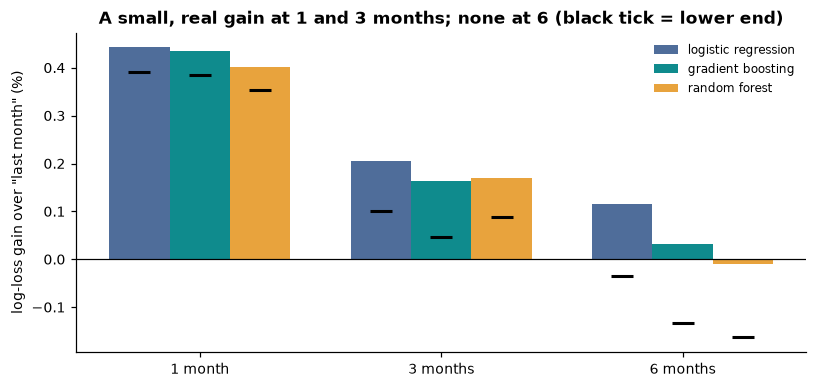

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colors = {"logistic": COL["blue"], "gbm": COL["teal"], "rf": COL["amber"]}
labels = {"logistic": "logistic regression", "gbm": "gradient boosting", "rf": "random forest"}
width = 0.25
for i, name in enumerate(["logistic", "gbm", "rf"]):
    gain = [100 * R["T2"][h]["scenarios"]["main"]["models"][name]["relative_gain"] for h in HS]
    base = [R["T2"][h]["scenarios"]["main"]["baseline_log_loss"][R["T2"][h]["scenarios"]["main"]["best_baseline"]] for h in HS]
    low = [100 * R["T2"][h]["scenarios"]["main"]["models"][name]["low"] / b for h, b in zip(HS, base)]
    x = np.arange(3) + (i - 1) * width
    ax.bar(x, gain, width, color=colors[name], label=labels[name])
    ax.plot(x, low, "_", color="k", ms=14, mew=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(3), [f"{h} month" + ("s" if h != "1" else "") for h in HS])
ax.set_ylabel("log-loss gain over \"last month\" (%)")
ax.set_title("A small, real gain at 1 and 3 months; none at 6 (black tick = lower end)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** All three models are promoted at 1 and 3 months, none at 6. The gain is small: about 0.4% of log-loss at 1 month (better in every one of the 46 test months), about 0.2% at 3 months (33 to 36 of 44 months), and about 0.1% at 6 months with a lower end below zero. The simplest promoted model, the logistic regression, serves at 1 and 3 months; at 6 months the baseline serves. The gradient boosting and the forest tie with the logistic regression, so the extra complexity buys nothing. The 1-month gain is in line with the archived attempt's "about 0.4%".

Caveat carried from DL-76: G4 was chosen on these same test months, so the models' advantage is slightly optimistic.

### Do the forecasts run too high or too low?

Visit-weighted predicted share over observed share, minus one. Positive means the forecast is too high.

In [7]:
rows = []
for h in HS:
    for name, c in R["T2"][h]["calibration"].items():
        rows.append({"horizon": int(h), "model": name, "predicted / observed - 1": c["ratio_minus_one"], "slope": c["slope"]})
calib = pd.DataFrame(rows)
display(calib.pivot(index="model", columns="horizon", values="predicted / observed - 1"))
size = pd.DataFrame({h: {k: v["ratio_minus_one"] for k, v in R["T2"][h]["calibration"]["logistic"]["by_size"].items()} for h in HS})
size = size.loc[["under 50", "50 to 199", "200 to 999", "1000 and over"]]
size.columns = [f"{h} month(s)" for h in HS]
print("logistic regression, by segment size (category visits at the origin)")
display(size)

horizon,1,3,6
model,,,
gbm,0.0433,0.1065,0.1837
logistic,0.0549,0.1092,0.1824
rf,0.0387,0.0980,0.1848


logistic regression, by segment size (category visits at the origin)


,1 month(s),3 month(s),6 month(s)
under 50,-0.0455,0.0385,0.0704
50 to 199,0.0330,0.0527,0.1186
200 to 999,0.0604,0.1245,0.2032
1000 and over,0.0566,0.1110,0.1834


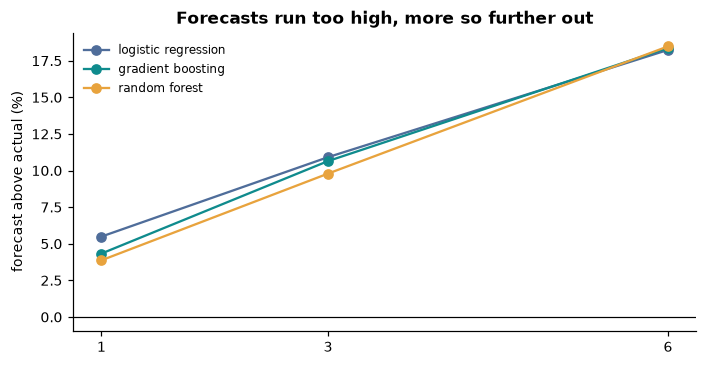

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name, color in [("logistic", COL["blue"]), ("gbm", COL["teal"]), ("rf", COL["amber"])]:
    ax.plot([int(h) for h in HS], [100 * R["T2"][h]["calibration"][name]["ratio_minus_one"] for h in HS], "o-", color=color, label=labels[name])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([1, 3, 6])
ax.set_ylabel("forecast above actual (%)")
ax.set_title("Forecasts run too high, more so further out")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** Every model runs too high, by about 4 to 6% at 1 month, 10 to 11% at 3 months and 18% at 6 months. This is the same bias the archived attempt found (about +7%) while the market was falling; the new inputs did not remove it. By size, the bias is largest for segments with 200 or more visits and slightly negative for the smallest (under 50 visits) at 1 month. The calibration slope is about 1.06 to 1.10. Calibration is reported, not a pass or fail test, but it means a user of the 3-month forecast should read it as optimistic.

## 4. T3: the decline alert (registered result)

The label is 1 when a segment's share is at least 30% below its share at the origin; only segments with a positive origin share and at least 100 category visits in the origin month are scored. PR-AUC is read against the decline share (what "always alert" scores). *Gain* and *lower end* are for the model against the best baseline, which is "small segment" at every horizon.

In [9]:
rows = []
for h in HS:
    d = R["T3"][h]["scenarios"]["main"]
    r = {"horizon": int(h), "test months": d["n_test_months"], "scored rows": d["n_rows"], "declines": d["n_positive"],
         "decline share (= always alert)": d["decline_share"]}
    for name in ["recent_drop", "small_segment", "logistic", "gbm", "rf"]:
        r[name] = d["methods"][name]["pr_auc"]
    rows.append(r)
pr = pd.DataFrame(rows)
display(pr)
rows = []
for h in HS:
    d = R["T3"][h]["scenarios"]["main"]
    for name, m in d["models"].items():
        rows.append({"horizon": int(h), "model": name, "best baseline": d["best_baseline"], "gain in PR-AUC": m["estimate"],
                     "lower end": m["low"], "promoted": m["promoted"]})
display(pd.DataFrame(rows))

,horizon,test months,scored rows,declines,decline share (= always alert),recent_drop,small_segment,logistic,gbm,rf
0,1,46,3183,729,0.2290,0.1520,0.3794,0.5535,0.5413,0.5161
1,3,44,3067,735,0.2396,0.1660,0.3659,0.5126,0.4586,0.4578
2,6,41,2893,824,0.2848,0.2068,0.3972,0.5100,0.4747,0.4809


,horizon,model,best baseline,gain in PR-AUC,lower end,promoted
0,1,gbm,small_segment,0.1619,0.1289,True
1,1,logistic,small_segment,0.1741,0.1386,True
2,1,rf,small_segment,0.1367,0.1038,True
3,3,gbm,small_segment,0.0927,0.0529,True
4,3,logistic,small_segment,0.1467,0.1104,True
5,3,rf,small_segment,0.0919,0.0508,True
6,6,gbm,small_segment,0.0775,0.0465,True
7,6,logistic,small_segment,0.1128,0.0835,True
8,6,rf,small_segment,0.0837,0.0494,True


Precision, recall and F1 at the alert threshold, which is chosen at each origin from earlier origins only. *Alerts* is how many of the test rows were flagged.

In [10]:
rows = []
for h in HS:
    d = R["T3"][h]["scenarios"]["main"]
    for name in ["always_alert", "small_segment", "logistic", "gbm", "rf"]:
        m = d["methods"][name]
        rows.append({"horizon": int(h), "method": name, "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                     "alerts": m["n_alerts"], "of rows": m["n_rows"]})
pd.DataFrame(rows)

,horizon,method,precision,recall,F1,alerts,of rows
0,1,always_alert,0.2290,1.0000,0.3727,3183,3183
1,1,small_segment,0.3590,0.7160,0.4782,1454,3183
2,1,logistic,0.4916,0.6420,0.5568,952,3183
3,1,gbm,0.4678,0.6173,0.5322,962,3183
4,1,rf,0.4776,0.5995,0.5316,915,3183
5,3,always_alert,0.2396,1.0000,0.3866,3067,3067
6,3,small_segment,0.3489,0.7224,0.4705,1522,3067
7,3,logistic,0.4508,0.6544,0.5339,1067,3067
8,3,gbm,0.4083,0.6694,0.5072,1205,3067
9,3,rf,0.4058,0.6449,0.4982,1168,3067


**Registered reading.** Under the registered baselines every classifier is promoted at every horizon, and the logistic regression serves. Its PR-AUC (about 0.55, 0.51 and 0.51) is more than double the decline share at 1 month, and at the chosen threshold it flags about 950 of 3,183 test rows with a precision near 0.49 and a recall near 0.64.

**But read section 5 before using this result.** One of the registered baselines points the wrong way.

## 5. Post hoc: how much of the T3 gain is regression to the mean?

*Added after the results were seen. It does not replace any registered result.*

The registered "recent drop" baseline scores a segment higher when its latest share is *below* its 3-month mean. It scored 0.15 to 0.21 PR-AUC, **below** the no-skill level of 0.23 to 0.29: it ranks segments in the wrong order. The reason is regression to the mean. A segment's monthly share is noisy; a month that spiked above its recent average tends to be followed by a fall, which is exactly what the label counts as a decline. I wrote the baseline's sign backwards, so the registered comparison was against a baseline that was worse than doing nothing.

The check below changes only that sign and nothing else.

In [11]:
rows = []
for h in HS:
    p = P["horizons"][h]
    rows.append({"horizon": int(h), "decline share": p["decline_share"], "registered recent drop": p["pr_auc_registered_recent_drop"],
                 "same score, sign flipped": p["pr_auc_flipped_recent_drop"], "logistic": p["pr_auc_logistic"],
                 "gain over flipped": p["gain_over_flipped"], "lower end (registered percentile)": p["lower_at_registered_percentile"],
                 "lower end (2.5th)": p["lower_at_2_5"]})
ph = pd.DataFrame(rows)
display(ph)

,horizon,decline share,registered recent drop,"same score, sign flipped",logistic,gain over flipped,lower end (registered percentile),lower end (2.5th)
0,1,0.2290,0.1520,0.5045,0.5535,0.0490,0.0126,0.0162
1,3,0.2396,0.1660,0.4937,0.5126,0.0189,-0.0130,-0.0061
2,6,0.2848,0.2068,0.5062,0.5100,0.0038,-0.0301,-0.0251


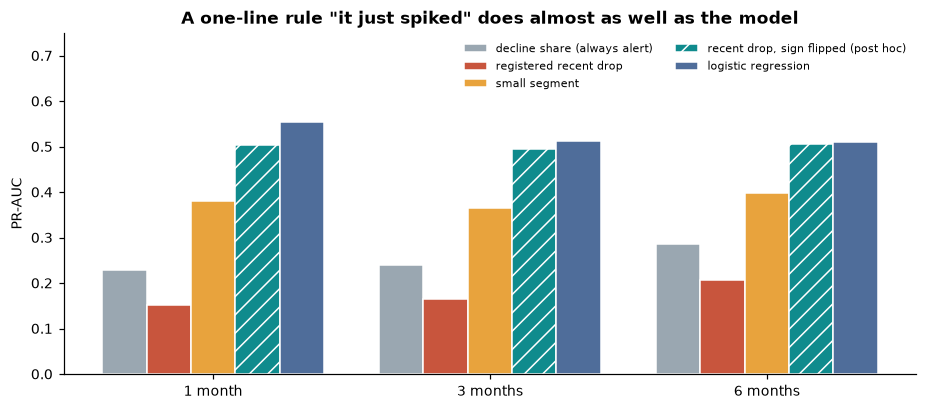

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
items = [("decline share (always alert)", [P["horizons"][h]["decline_share"] for h in HS], COL["base"], ""),
         ("registered recent drop", [P["horizons"][h]["pr_auc_registered_recent_drop"] for h in HS], COL["rust"], ""),
         ("small segment", [R["T3"][h]["scenarios"]["main"]["methods"]["small_segment"]["pr_auc"] for h in HS], COL["amber"], ""),
         ("recent drop, sign flipped (post hoc)", [P["horizons"][h]["pr_auc_flipped_recent_drop"] for h in HS], COL["teal"], "//"),
         ("logistic regression", [P["horizons"][h]["pr_auc_logistic"] for h in HS], COL["blue"], "")]
width = 0.16
for i, (label, vals, color, hatch) in enumerate(items):
    ax.bar(np.arange(3) + (i - 2) * width, vals, width, color=color, hatch=hatch, label=label, edgecolor="white")
ax.set_xticks(range(3), [f"{h} month" + ("s" if h != "1" else "") for h in HS])
ax.set_ylabel("PR-AUC")
ax.set_title("A one-line rule \"it just spiked\" does almost as well as the model")
ax.legend(frameon=False, fontsize=7.5, ncol=2, loc="upper right")
ax.set_ylim(0, 0.75)
plt.tight_layout()
plt.show()

**Reading.**

- Flipping that one sign lifts the baseline from 0.15 to **0.50** at 1 month and to 0.49 to 0.51 at 3 and 6 months, close to the models' 0.51 to 0.55.
- The logistic regression still beats the flipped baseline reliably at **1 month** (gain +0.049; lower end +0.013 at the 1.67th percentile). At **3 months** the gain is +0.019 with a lower end of -0.013, and at **6 months** it is +0.004 with a lower end of -0.030: not distinguishable from zero.
- So most of the registered T3 result is the statistical fact that a spiked month falls back. That is real and predictable, but it is not a business insight, and it says nothing about why a segment's share is going down.
- The post-hoc flipped baseline was not registered, so it cannot promote or demote anything. It is reported so that the T3 result is not over-read. The plan's rules were followed exactly; the weakness was in the baseline I wrote.

## 6. Robustness and the other scenarios

Each scenario re-runs the whole walk with the rows removed. *Promoted* lists the trained models whose lower end is above zero; *serving* is the model the rule chooses.

In [13]:
rows = []
for task, key in [("T2", "T2"), ("T3", "T3")]:
    for h in HS:
        for scen, d in R[key][h]["scenarios"].items():
            rows.append({"task": task, "horizon": int(h), "scenario": scen, "promoted": ", ".join(d["promoted"]) or "none",
                         "serving": d["serving"], "test months": d["n_test_months"]})
sc = pd.DataFrame(rows)
display(sc.pivot_table(index=["task", "horizon"], columns="scenario", values="serving", aggfunc="first"))
display(sc.pivot_table(index=["task", "horizon"], columns="scenario", values="promoted", aggfunc="first"))

scenario     covid_removed dip_2024_removed   fall_20   fall_50        main pediatrics_removed
task horizon                                                                                  
T2   1            logistic         logistic       NaN       NaN    logistic           logistic
     3            logistic         logistic       NaN       NaN    logistic           logistic
     6          last_month       last_month       NaN       NaN  last_month         last_month
T3   1            logistic         logistic  logistic  logistic    logistic           logistic
     3            logistic         logistic  logistic  logistic    logistic           logistic
     6            logistic         logistic  logistic  logistic    logistic           logistic

scenario          covid_removed   dip_2024_removed            fall_20            fall_50               main pediatrics_removed
task horizon                                                                                                                  
T2   1        logistic, gbm, rf  logistic, gbm, rf                NaN                NaN  logistic, gbm, rf  logistic, gbm, rf
     3        logistic, gbm, rf  logistic, gbm, rf                NaN                NaN  logistic, gbm, rf  logistic, gbm, rf
     6                     none               none                NaN                NaN               none               none
T3   1        logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf
     3        logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf
     6        logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf  logistic, gbm, rf

**Reading.** The T2 pattern does not depend on the COVID months, the 2024 dip or PEDIATRICS: promoted at 1 and 3 months and not at 6, whatever is removed. At 3 months the gain is about 0.17 to 0.27% of log-loss in every scenario. The 20% and 50% fall rules in T3 give the same picture as the 30% rule: all three classifiers promoted at every horizon, with the logistic regression highest. T1 without the 2024 dip is the same story as the main run.

## 7. The labelled G5 hypothesis (competitor volumes)

The logistic regression on B0 + G4 + G5 against B0 + G4, at 1 and 3 months, each at the 2.5th percentile. Outside promotion.

In [14]:
pd.DataFrame([{"horizon": int(h), "gain": g["estimate"], "lower end": g["low"], "log-loss without G5": g["log_loss_base"],
               "log-loss with G5": g["log_loss_with_g5"], "passes": g["passes"], "test months": g["n_test_months"]}
              for h, g in R["G5"].items()])

,horizon,gain,lower end,log-loss without G5,log-loss with G5,passes,test months
0,1,-0.0000,-0.0001,0.1127,0.1127,False,46
1,3,0.0000,-0.0001,0.1119,0.1119,False,44


G5 does not pass at either horizon (1 month: slightly worse; 3 months: no difference), so it is not stored. The earlier pass under the t-2 lag (DL-76) did not carry over.

## 8. The batch demonstration

Data stopped at a cut-off; the serving models predict the six following months as one batch. The national number uses "same as last month" (the serving model at every horizon) with its 90% range; the segment forecast uses the logistic regression for months 1 to 4 and the baseline for months 5 to 6 (the serving model of the nearest evaluated horizon). This is descriptive, not a pass or fail test.

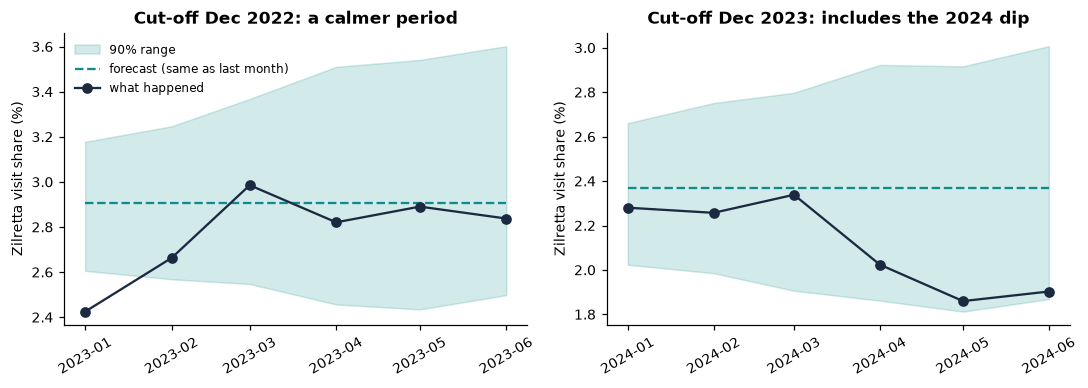

actual inside the 90% range in 11 of 12 months


In [15]:
nat = pd.DataFrame(R["demonstration"]["national"])
nat["date"] = pd.to_datetime(nat["month_id"].astype(str) + "01", format="%Y%m%d")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, cutoff, title in zip(axes, [202212, 202312], ["Cut-off Dec 2022: a calmer period", "Cut-off Dec 2023: includes the 2024 dip"]):
    d = nat[nat["cutoff"] == cutoff]
    ax.fill_between(d["date"], d["lo90"], d["hi90"], color=COL["teal"], alpha=0.18, label="90% range")
    ax.plot(d["date"], d["point"], "--", color=COL["teal"], label="forecast (same as last month)")
    ax.plot(d["date"], d["actual"], "o-", color="#1b2a41", label="what happened")
    ax.set_title(title)
    ax.set_ylabel("Zilretta visit share (%)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
inside = ((nat["actual"] >= nat["lo90"]) & (nat["actual"] <= nat["hi90"]))
print(f"actual inside the 90% range in {int(inside.sum())} of {len(nat)} months")

In [16]:
seg = pd.DataFrame(R["demonstration"]["segment"])
agg = seg.groupby(["cutoff", "step"]).agg(visits=("visits", "sum"), predicted=("predicted_visits", "sum"), actual=("actual_visits", "sum")).reset_index()
agg["predicted share %"] = 100 * agg["predicted"] / agg["visits"]
agg["actual share %"] = 100 * agg["actual"] / agg["visits"]
agg["forecast too high by %"] = 100 * (agg["predicted"] / agg["actual"] - 1)
agg[["cutoff", "step", "predicted share %", "actual share %", "forecast too high by %"]]

,cutoff,step,predicted share %,actual share %,forecast too high by %
0,202212,1,3.0553,2.4367,25.3860
1,202212,2,2.9948,2.6773,11.8567
2,202212,3,2.9828,2.9975,-0.4891
3,202212,4,2.9737,2.8433,4.5855
4,202212,5,3.0074,2.9086,3.3978
5,202212,6,3.0232,2.8493,6.1017
6,202312,1,2.5912,2.2871,13.2974
7,202312,2,2.6862,2.2566,19.0360
8,202312,3,2.7762,2.3514,18.0673
9,202312,4,2.8665,2.0351,40.8500


**Reading.** Nationally the flat forecast lands inside its 90% range in 11 of 12 months (the exception is the first month after December 2022, when the share fell below the range), and the range widens with the horizon. For the segments (all segments together), the December 2022 batch is mixed: 25% too high in the first month, then between about 1% too low and 12% too high. The December 2023 batch, which runs into the 2024 dip, is too high in every month, by 13 to 19% in the first three and 30 to 41% in the last three. That is the T2 calibration bias, seen in a concrete case, and it is the clearest picture of what the forecast cannot do: it cannot see a turn coming.

## 9. What this means

| Task | Result under the plan | Honest reading |
|---|---|---|
| **T1** national share | no model beats "same as last month" at 1, 3 or 6 months | the national share is best forecast by its last value; ranges from the trained models are unreliable |
| **T2** segment share | the logistic regression is promoted and serves at 1 and 3 months; the baseline serves at 6 | a real but small gain (about 0.4% then 0.2% of log-loss) that runs too high, increasingly so further out |
| **T3** decline alert | all three classifiers promoted at every horizon | most of the gain is regression to the mean (post hoc, section 5); only the 1-month alert shows a reliable gain over a one-line "it just spiked" rule |
| **G5** | does not pass | competitor volumes do not help |

**Limits.** 72 months of data, one change in direction, no monthly drivers we can observe, and overlapping origins make the 3 and 6 month results weaker than the 1 month one. G4 was chosen on the same test months. The registered pass rule is a significance rule with no minimum effect size, so "promoted" does not mean "worth a change"; adopting a model into serving is a separate decision (DL-79).